<a href="https://colab.research.google.com/github/ColeUmland/DSC-420-Midterm-Kaggle-Competition/blob/main/submission_csv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

playground_series_s6e10_path = kagglehub.competition_download('playground-series-s6e10')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


# Introduction
Prediction Problem: We are trying to if a passenger will be satisfied with their flight using several predictor columns. The dataset contains almost 700,000 observations. There are 18 available variables.

Response Variable: Our response variable is `satisfaction`. We want to know if we can predict the satisfaction a passenger will have based on certain in-flight characteristics.

In [ ]:
train = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")

# EDA
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


# Data Exploration
The dataset contains both numerical and categorical variables. The numerical variables include passenger information such as age and flight distance, as well as service ratings and departure and arrival delays. The categorical variables include gender, customer type, type of travel, class, and satisfaction. The summary statistics for the numerical variables show their ranges, means, and standard deviations, which helps identify the typical passenger and possible unusual values in the data.

In [ ]:
# Table of Missing Value counts
missing_table = pd.DataFrame({
    "Missing Values": train.isnull().sum(),
    "Percent Missing": train.isnull().mean() * 100
})
missing_table

,Missing Values,Percent Missing
id,0,0.000000
Age,0,0.000000
Flight Distance,0,0.000000
Inflight wifi service,0,0.000000
Departure/Arrival time convenient,0,0.000000
Ease of Online booking,0,0.000000
Gate location,0,0.000000
Food and drink,0,0.000000
Online boarding,0,0.000000
Seat comfort,0,0.000000


# Missing Values
The only predictor with missing values was `Arrival Delay in Minutes`. To fill these 292 missing values, we calculated the average difference between arrival delay and departure delay for observations where both values were available. I then added this average difference to each passenger's departure delay to estimate their missing arrival delay. I chose this method because arrival and departure delays are strongly related, so using the passenger's actual departure delay provides a more reasonable estimate than just replacing every missing value with the overall median.

In [ ]:
# Handling Missing Values
# Calculate the mean delay difference using training data only
delay_difference = (
    train["Arrival Delay in Minutes"] -
    train["Departure Delay in Minutes"]
).mean()

# Apply the same missing-value handling to train and test
for df in [train, test]:
    df["Arrival Delay in Minutes"] = df[
        "Arrival Delay in Minutes"
    ].fillna(
        df["Departure Delay in Minutes"] + delay_difference
    )

# Distribution and Correlation Matrix Findings
Distribution: The response variable is categorical, so either satisfied or not satisfied. This calls for classification models

Correlation Matrix Findings: Several predictors appear to be correlated with one another. `Departure Delay in Minutes` and `Arrival Delay in Minutes`. This is an example of two predictors telling a similar story. We might run into multicollinearity here.

- When it comes to correlation with our response variable, `satisfaction`, it seems `Flight Distance`, `Online boarding`, and `Inflight entertainment` have positive correlations with our response variable. We'll come back to this when we are choosing our predictors.

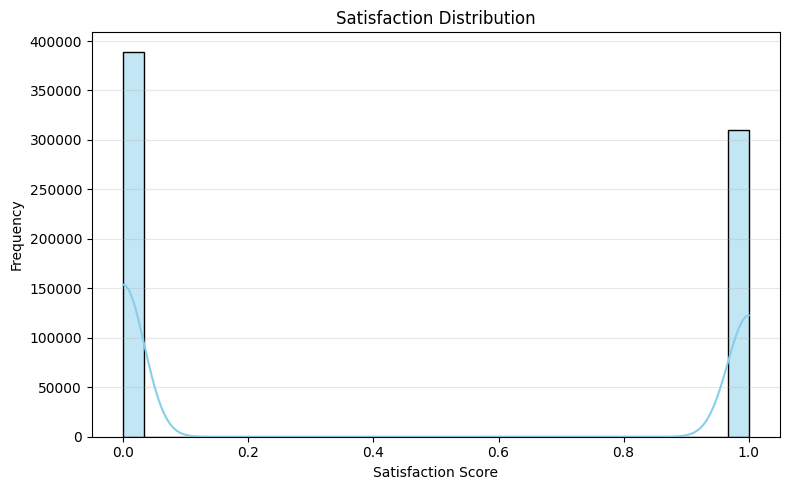

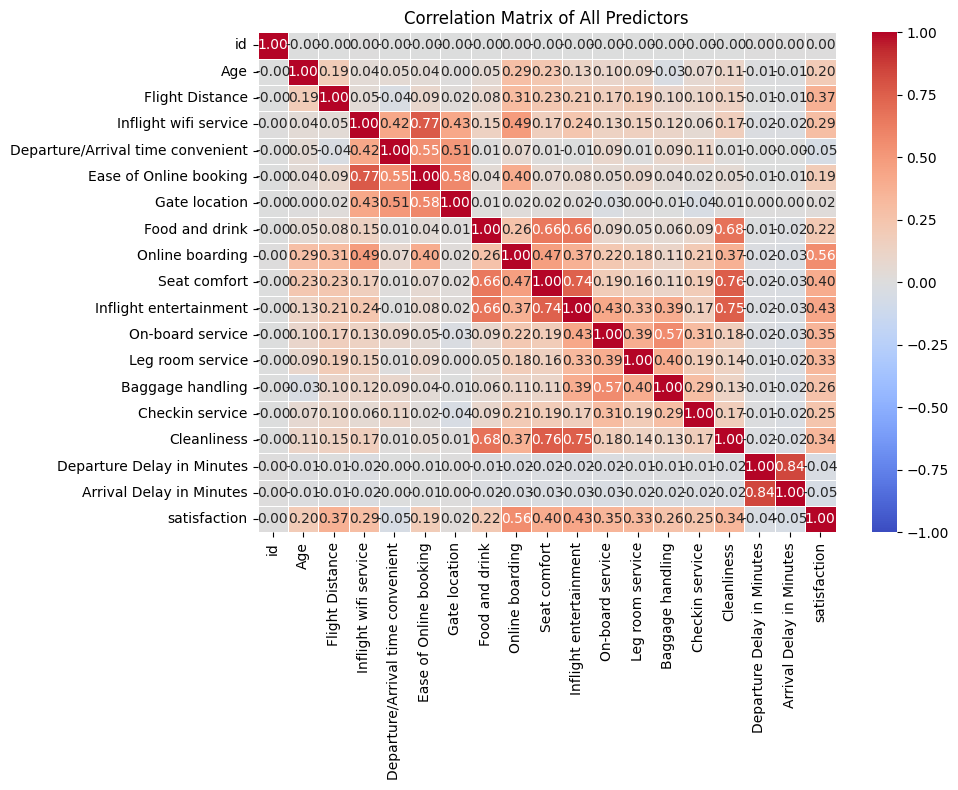

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

####### 2. Response Distribution & Correlation Plot of All Predictors ############

# --- A. Response Distribution ---
plt.figure(figsize=(8, 5))
# Pass x as a string column name when specifying data=train
sns.histplot(data=train, x='satisfaction', kde=True, bins=30, color='skyblue', edgecolor='black')

plt.title('Satisfaction Distribution')
plt.xlabel('Satisfaction Score')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# --- B. Correlation Plot of All Predictors ---
plt.figure(figsize=(10, 8))
# Calculate Pearson correlation matrix for numeric columns
corr_matrix = train.corr(numeric_only=True)

# Heatmap visualization
sns.heatmap(
    corr_matrix,
    annot=True,         # Display numerical values in cells
    fmt='.2f',          # Format numbers to 2 decimal places
    cmap='coolwarm',    # Color palette (blue = negative, red = positive correlation)
    vmin=-1, vmax=1,    # Scale range
    linewidths=0.5
)

plt.title('Correlation Matrix of All Predictors')
plt.tight_layout()
plt.show()

# Exploratory Data Analysis

Dropping Unessecary Predictors: `id` is essentialy just a row count in this example and will have no predictive power besides noise. Therefore we drop the `id` column from our model.

# Handling Skewed Delays
Since our delay columns (`Arrival Delay` & `Departure Delay`) are very right skewed. That is, they have a median close to zero with a mean that is pulled up by the very large delay outliers. In an effort to standardize these, we are going to take the loge of them. Now they will appear more linear.

# Feature Engineering
`Departure Delay` and `Arrival Delay` seem to be correlated via the correlation matrix above. If your plane takes off late, there is a great chance it will land late as well. By adding an interaction term, our model can account for this covariance.

# Composite Survey Scores
In the correlation matrix, the in-flight survey scores seem to correlate moderately. All of these variables are on a Likert scale. So, to account for this correlation, we created an interaction term between all of these in-flight survey variables to account for their covariance. This was done by taking the average of all of the survey scores and putting them into a new metric.

In [ ]:
################ 3 #################
def preprocess_airline_data(df):
    df = df.copy()

    # 1. Dropping the `id` column. It isn't applicable in our model
    if 'id' in df.columns:
        df = df.drop(columns=['id'])

    # 2. Handle Skewed Delays & Feature Engineering
    # Since our delay columns are very heavily right-skewed, we are taking the log of those two columns as an effort to standardize them
    # Then we are creating an interaction term between departure and arrival delay as they are deemed to be very correlated in our correlation heat map above.
    # This is done after the log is taken
    df['Departure Delay Log'] = np.log1p(df['Departure Delay in Minutes'])
    df['Arrival Delay Log'] = np.log1p(df['Arrival Delay in Minutes'])
    df['Total_Delay'] = df['Departure Delay Log'] + df['Arrival Delay Log']

    # 3 Composite Survey Scores
    # Taking several correlated "inflight" rating metrics and combining them
    # In the heat map, they were seen to correlate amongst themselves
    # Creating a new column that takes the average of each row's score across the metrics into one metric
    inflight_cols = ['Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Cleanliness', 'Food and drink']
    df['Inflight_Score_Avg'] = df[inflight_cols].mean(axis=1)

    # Returning the altered data frame at the end of this function
    return df

# Usage:
train_cleaned = preprocess_airline_data(train)
# Updating the test set as well
test = preprocess_airline_data(test)
train_cleaned.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Departure Delay Log,Arrival Delay Log,Total_Delay,Inflight_Score_Avg
count,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,...,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000
mean,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,...,3.472847,3.805443,3.420291,3.380401,1.176209,1.136894,0.200013,0.193476,0.393489,3.443193
std,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,...,1.271755,1.079175,1.210604,1.277870,5.982187,5.767975,0.692227,0.687499,1.251072,0.916566
min,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,-0.039315,0.000000,-0.040109,-0.040109,0.666667
25%,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,...,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.666667
50%,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,...,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.666667
75%,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,...,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.166667
max,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000,6.194405,6.198479,12.392884,5.000000


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = train_cleaned.drop(columns=["satisfaction"])
y = train_cleaned["satisfaction"]

# Encode the response variable
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Identify numerical and categorical predictors
num_cols = X.select_dtypes(include=np.number).columns.tolist()

cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Split the data into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Numerical predictors:", len(num_cols))
print("Categorical predictors:", len(cat_cols))

Training rows: 559708
Validation rows: 139927
Numerical predictors: 21
Categorical predictors: 4


In [ ]:
# Step 4: Logistic Regression

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_probs = logistic_model.predict_proba(X_valid)[:, 1]
logistic_auc = roc_auc_score(y_valid, logistic_probs)

print("Logistic Regression ROC AUC:", round(logistic_auc, 5))

Logistic Regression ROC AUC: 0.9206


In [ ]:
# Random Forest Model

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_probs = random_forest_model.predict_proba(X_valid)[:, 1]
rf_auc = roc_auc_score(y_valid, rf_probs)

print("Random Forest ROC AUC:", round(rf_auc, 5))



Random Forest ROC AUC: 0.95413


In [ ]:
# CatBoost Gradient Booster

from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=1000,
    depth=7,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=50,
    allow_writing_files=False,
    thread_count=-1
)

catboost_model.fit(
    X_train,
    y_train,
    cat_features=cat_cols,
    eval_set=(X_valid, y_valid)
)

catboost_probs = catboost_model.predict_proba(X_valid)[:, 1]
catboost_auc = roc_auc_score(y_valid, catboost_probs)

print("CatBoost ROC AUC:", round(catboost_auc, 5))




0:	test: 0.9424959	best: 0.9424959 (0)	total: 336ms	remaining: 5m 36s
100:	test: 0.9545477	best: 0.9545477 (100)	total: 27.4s	remaining: 4m 3s
200:	test: 0.9560608	best: 0.9560608 (200)	total: 54.7s	remaining: 3m 37s
300:	test: 0.9566779	best: 0.9566779 (300)	total: 1m 21s	remaining: 3m 10s
400:	test: 0.9570063	best: 0.9570064 (399)	total: 1m 48s	remaining: 2m 42s
500:	test: 0.9571645	best: 0.9571657 (499)	total: 2m 15s	remaining: 2m 14s
600:	test: 0.9572930	best: 0.9572930 (600)	total: 2m 42s	remaining: 1m 47s
700:	test: 0.9573780	best: 0.9573780 (699)	total: 3m 9s	remaining: 1m 20s
800:	test: 0.9574416	best: 0.9574416 (800)	total: 3m 36s	remaining: 53.8s
900:	test: 0.9574794	best: 0.9574796 (892)	total: 4m 3s	remaining: 26.7s
999:	test: 0.9574967	best: 0.9575025 (993)	total: 4m 29s	remaining: 0us

bestTest = 0.957502493
bestIteration = 993

Shrink model to first 994 iterations.
CatBoost ROC AUC: 0.9575


# Model Comparison
|Model|Test AUC |
|---|---|
|Logistic Regression | .9206 |
|Random Forests | .95413 |
|CatBoost | .9575 |

Which model perfomred the best on the validation set?
- The CatBoost model had the best performance with an AUC of .9575. Interpretting this, if our model was given a pair of observations, one satisfied passenger and one dissatisfied passenger, the model would give a higher likelihood of being satisfied the the truely satisfied passenger 95.75% of the time.

The Flexible Models outperformed the less flexible model.
- The CatBoost and Random forests designs are an ensemble approach.Since these both did better than logistic regression, it can be inferred that our data is non-linear and has many interactions.

CatBoost did slightly better than Random Forrests
- CatBoost beat our Random Forests by .00337 in AUC. Random Forrests' bagging was beat out by CatBoost's gradient boosting.

# Identify Important Predictors

# Submitting to Competition Steps

In [ ]:
# KAGGLE SUBMISSION: CATBOOST

# 1. Load the sample submission file
sample_submission = pd.read_csv(
    "/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv"
)

# 2. Create test features using the same preprocessing
X_test = test.drop(columns=["satisfaction"], errors="ignore")

# 3. Ensure test columns match the model's training features
X_test = X_test[X_train.columns]

# 4. Predict probabilities for the positive class
test_probs = catboost_model.predict_proba(X_test)[:, 1]

# 5. Fill the required submission columns
submission = sample_submission.copy()
submission["satisfaction"] = test_probs

# 6. Verify the submission
print("Submission columns:", submission.columns.tolist())
print("Submission shape:", submission.shape)
print(submission.head())
print("Missing predictions:", submission["satisfaction"].isna().sum())

# 7. Save the CSV file
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("CSV saved successfully!")


Submission columns: ['id', 'satisfaction']
Submission shape: (299844, 2)
       id  satisfaction
0  699635      0.271135
1  699636      0.893046
2  699637      0.891580
3  699638      0.066001
4  699639      0.063472
Missing predictions: 0
CSV saved successfully!
